# Búsqueda de hiperparámetros para modelos no supervisados

* **Objetivo:** evaluar distintas configuraciones de K-Means y DBSCAN mediante búsqueda exhaustiva y aleatoria, comparando su desempeño sobre dos representaciones reducidas con PCA.

El notebook desarrolla el proceso de selección de componentes, preparación de muestras, definición de espacios de búsqueda, evaluación de configuraciones y comparación de resultados.

**Operaciones principales:**
- Preparación de representaciones PCA de 9 y 13 componentes.
- Evaluación de K-Means y DBSCAN con Grid Search y Randomized Search.
- Selección de configuraciones mediante métricas internas de clustering.
- Comparación de resultados y visualización del comportamiento de los modelos.

---

In [ ]:
import numpy as np
import pandas as pd
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)


"""
En caso de que Python no encuentre en la ruta los otros directorios,
ejecutar esta configuración*
"""

sys.path.append(os.path.abspath(".."))

## Importación de librerías y carga de datos

Se importan las herramientas necesarias para manipular los datos, reducir dimensionalidad, ejecutar los algoritmos de clustering, generar combinaciones de hiperparámetros y calcular métricas de evaluación.

Posteriormente, se carga el dataset preprocesado y se crea una copia de trabajo para mantener separado el origen de los datos.

In [2]:
data = pd.read_csv("../../dataset/spotify_train_preprocesado_general.csv")

df = data.copy()

df.head()

,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity_category
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.360656,0.407609,0.005418,...,-0.557598,0.751125,-0.804229,0.532848,-0.562123,-0.436477,1.542740,-0.147610,-0.695300,1
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.360656,0.100464,-0.034422,...,-0.017461,0.751125,-0.785413,0.623235,-0.606882,-0.678120,1.183864,0.437714,-0.191994,0
2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.927115,-1.881489,0.216573,...,0.430609,0.751125,-0.519639,-0.618079,-0.580263,-0.985860,-1.305115,0.437984,0.625209,2
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.360656,1.746296,0.336094,...,0.571210,-1.331337,-0.500823,-0.710274,-0.606882,-0.635477,-0.506326,0.064335,-0.879964,0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,-0.360656,0.726344,-1.795371,...,-2.390784,-1.331337,1.124396,1.430692,1.793755,-0.671013,1.195440,2.664353,-0.772929,2


---

# Selección de componentes PCA



Con el fin de seleccionar el número de componentes adecuado y **corroborar su impacto en el análisis**, se utilizarán dos dataframes con distinta cantidad de componentes los cuales se componenen de la siguiente manera:



Dataframe 1:

* Número de componentes: 9

* Varianza acumulada: 81,59%

* Representación de datos: 45%



Dataframe 2:

* Número de componentes: 13

* Varianza acumulada: 90,81%

* Representación de datos: 65%

## Selección de componentes PCA

Se seleccionan las variables que serán utilizadas para construir las representaciones reducidas. Estas corresponden a las características codificadas y numéricas definidas previamente en el proceso de preprocesamiento.

Se trabajará con dos representaciones para analizar cómo la cantidad de componentes puede influir en la formación y evaluación de los clusters.

In [3]:
features_pca = [
    "bin__track_genre_0",
    "bin__track_genre_1",
    "bin__track_genre_2",
    "bin__track_genre_3",
    "bin__track_genre_4",
    "bin__track_genre_5",
    "bin__track_genre_6",
    "ord__duration_category",
    "num__danceability",
    "num__energy",
    "num__key",
    "num__loudness",
    "num__mode",
    "num__speechiness",
    "num__acousticness",
    "num__instrumentalness",
    "num__liveness",
    "num__valence",
    "num__tempo",
    "num__duration_min"
]

X_pca = df[features_pca]

Con fines de análisis a mayor profundidad, se manejarán 2 dataframes los cuales tendrán componentes PCA distintos:



* PCA1 con 9 componentes

* PCA2 con 13 componentes

### Generación de representaciones PCA

Se ajustan dos modelos PCA: uno conserva 9 componentes y el otro 13. Ambos modelos se entrenan sobre las mismas variables de entrada, permitiendo comparar los resultados bajo distintas cantidades de información retenida.

In [4]:
pca1 = PCA(n_components = 9)
pca2 = PCA(n_components = 13)


X_pca_df1 = pca1.fit_transform(X_pca)
X_pca_df2 = pca2.fit_transform(X_pca)

Creación del Dataframe con los componentes

### Creación de DataFrames con componentes

Los resultados transformados se almacenan en DataFrames, asignando nombres consecutivos a los componentes principales (`PC1`, `PC2`, etc.).

Se incorpora `popularity_category` únicamente como variable auxiliar para realizar muestreos estratificados y análisis posteriores. Esta columna se excluye de las matrices utilizadas por los algoritmos de clustering.

In [5]:
df_pca_1 = pd.DataFrame(
    X_pca_df1,
    columns=[f"PC{i}" for i in range(1, pca1.n_components_ + 1)],
    index=df.index
)

df_pca_1["popularity_category"] = df["popularity_category"]


df_pca_2 = pd.DataFrame(
    X_pca_df2,
    columns=[f"PC{i}" for i in range(1, pca2.n_components_ + 1)],
    index=df.index
)

df_pca_2["popularity_category"] = df["popularity_category"]

In [6]:
df_pca_1.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,popularity_category
0,-0.200809,-1.375739,1.229657,0.260928,0.175410,1.301302,-0.213395,0.526588,0.631094,1
1,-0.070853,-0.885718,0.933779,0.659522,-0.334985,1.296782,0.063861,0.117424,0.242782,0
2,-0.143451,1.765934,-0.788070,0.426808,-0.482869,1.772724,-0.813168,0.414526,-1.460656,2
3,1.108933,-0.815601,0.887455,-1.884844,-0.158095,0.821274,-0.896440,-0.363621,-0.273614,0
4,-2.034280,-1.121345,0.131627,-1.367931,-1.711352,-0.524165,3.779628,-1.182260,1.592352,2


In [7]:
df_pca_2.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,popularity_category
0,-0.200809,-1.375739,1.229657,0.260928,0.175410,1.301302,-0.213395,0.526588,0.631094,0.585176,-0.144823,0.062624,-0.054573,1
1,-0.070853,-0.885718,0.933779,0.659522,-0.334985,1.296782,0.063861,0.117424,0.242782,0.571305,0.086036,0.044179,-0.056428,0
2,-0.143451,1.765934,-0.788070,0.426808,-0.482869,1.772724,-0.813168,0.414526,-1.460656,0.259746,-0.392587,-0.103014,-0.101921,2
3,1.108933,-0.815601,0.887455,-1.884844,-0.158095,0.821274,-0.896440,-0.363621,-0.273614,-1.327553,0.229204,0.035569,-0.013113,0
4,-2.034280,-1.121345,0.131627,-1.367931,-1.711352,-0.524165,3.779628,-1.182260,1.592352,0.443039,-0.276758,0.123554,0.287918,2


---

## Preparación de datos para clustering

Se generan las matrices de entrada para cada representación PCA, excluyendo la variable auxiliar de popularidad. De esta forma, K-Means y DBSCAN reciben únicamente los componentes principales.

# Proceso de K-means y Clusters

Buscando el número adecuado de clusters

In [8]:
# 9 Dimensiones
X_cluster_1 = df_pca_1.drop(columns="popularity_category")
# 13 Dimensiones
X_cluster_2 = df_pca_2.drop(columns="popularity_category")


Puesto que nuestro dataset contiene muchos datos, silhouette Score **no ejecutará** puesto que es costoso computacionalmente, por lo qué se creará un muestreo estratificado.

### Muestreo estratificado

Debido al tamaño del dataset, se utiliza una muestra de 15.000 observaciones para reducir el costo computacional de la búsqueda y del cálculo de Silhouette.

El muestreo se estratifica mediante `popularity_category`, con el propósito de conservar aproximadamente la distribución de esta variable en ambas representaciones PCA. La semilla aleatoria permite reproducir la selección.

In [9]:
df_muestra_pca9, _ = train_test_split(
    df_pca_1,
    train_size=15000,
    stratify=df_pca_1["popularity_category"],
    random_state=42
)


df_muestra_pca13, _ = train_test_split(
    df_pca_2,
    train_size=15000,
    stratify=df_pca_2["popularity_category"],
    random_state=42
)

### Verificación de la distribución de las muestras

Se comparan las proporciones de cada categoría en el dataset original y en las muestras. Esta comprobación permite verificar que el muestreo estratificado mantiene una distribución similar.

In [10]:
print("Distribución original PCA 9:")
print(df_pca_1["popularity_category"].value_counts(normalize=True))


print("\nDistribución muestra PCA 9:")
print(df_muestra_pca9["popularity_category"].value_counts(normalize=True))


print("\nDistribución original 13:")
print(df_pca_2["popularity_category"].value_counts(normalize=True))


print("\nDistribución muestra 13:")
print(df_muestra_pca13["popularity_category"].value_counts(normalize=True))

Distribución original PCA 9:
popularity_category
0    0.297189
2    0.291634
1    0.291623
3    0.111156
4    0.008398
Name: proportion, dtype: float64

Distribución muestra PCA 9:
popularity_category
0    0.297200
2    0.291667
1    0.291600
3    0.111133
4    0.008400
Name: proportion, dtype: float64

Distribución original 13:
popularity_category
0    0.297189
2    0.291634
1    0.291623
3    0.111156
4    0.008398
Name: proportion, dtype: float64

Distribución muestra 13:
popularity_category
0    0.297200
2    0.291667
1    0.291600
3    0.111133
4    0.008400
Name: proportion, dtype: float64


# Creación de muestras Silhouette

### Matrices de evaluación

Se extraen exclusivamente las columnas de componentes principales de cada muestra. Estas matrices serán utilizadas para evaluar las configuraciones de K-Means y DBSCAN.

In [11]:
X_muestra_pca9 = df_muestra_pca9[
    [f"PC{i}" for i in range(1, 10)]
]


X_muestra_pca13 = df_muestra_pca13[
    [f"PC{i}" for i in range(1, 14)]
]

## Definición de espacios de búsqueda

Se establecen los valores candidatos para los hiperparámetros de cada algoritmo. La búsqueda se realiza sobre espacios acotados para controlar el tiempo de ejecución y permitir una comparación entre Grid Search y Randomized Search.

### Hiperparámetros de K-Means

| Parámetro | Descripción |
|---|---|
| `n_clusters` | Cantidad de clusters que se desea formar. |
| `init` | Método utilizado para seleccionar los centroides iniciales. |
| `n_init` | Cantidad de inicializaciones independientes del algoritmo. |
| `max_iter` | Número máximo de iteraciones por ejecución. |

### Hiperparámetros de DBSCAN

| Parámetro | Descripción |
|---|---|
| `eps` | Distancia máxima para considerar que dos observaciones pertenecen al mismo vecindario. |
| `min_samples` | Cantidad mínima de observaciones necesarias para considerar una región como densa. |

`n_iter` define cuántas combinaciones se seleccionarán en la búsqueda aleatoria y `random_state` permite reproducir esa selección.

In [12]:
# Espacio de búsqueda para K-means
parametros_kmeans = {
    "n_clusters": [3, 4, 5, 6, 7, 8],
    "init": ["k-means++", "random"],
    "n_init": [10, 20],
    "max_iter": [300]
}


# Espacio de búsqueda para DBSCAN
parametros_dbscan = {
    "eps": [0.5, 0.75, 1.0, 1.25, 1.5],
    "min_samples": [5, 10, 15, 20]
}


n_iter = 10
random_state = 42


print("COMBINACIONES K-MEANS:",
      len(list(ParameterGrid(parametros_kmeans))))


print("COMBINACIONES DBSCAN:",
      len(list(ParameterGrid(parametros_dbscan))))

COMBINACIONES K-MEANS: 24
COMBINACIONES DBSCAN: 20


## Funciones de evaluación

Se definen funciones independientes para evaluar cada algoritmo con una configuración determinada. Ambas funciones entrenan el modelo, obtienen las etiquetas asignadas y calculan métricas internas cuando la solución contiene al menos dos clusters válidos.

### Evaluación de K-Means

La función recibe una matriz de datos y un conjunto de hiperparámetros. Después de ajustar K-Means, calcula:

- **Silhouette:** valores mayores indican una mejor separación y cohesión de los clusters.
- **Calinski-Harabasz:** valores mayores representan una mayor separación entre clusters respecto de su dispersión interna.
- **Davies-Bouldin:** valores menores indican clusters más compactos y separados.

Silhouette se calcula sobre una submuestra de hasta 2.000 observaciones para reducir el costo computacional; las otras dos métricas se calculan sobre el conjunto recibido.

In [13]:
def evaluar_kmeans(X, parametros):
# Crear modelo
    modelo = KMeans(
        n_clusters=parametros["n_clusters"],
        init=parametros["init"],
        n_init=parametros["n_init"],
        max_iter=parametros["max_iter"],
        random_state=42
    )

# Entrenar modelo y obtener etiquetas
    labels = modelo.fit_predict(X)

# Cantidad de clusters encontrados
    n_clusters = len(np.unique(labels))

# Calcular métricas
    silhouette = np.nan
    calinski = np.nan
    davies = np.nan

    if 2 <= n_clusters < len(X):
        silhouette = silhouette_score(
            X,
            labels,
            sample_size=min(2000, len(X)),
            random_state=42
        )


        calinski = calinski_harabasz_score(
            X,
            labels
        )


        davies = davies_bouldin_score(
            X,
            labels
        )


    return {
        **parametros,
        "Clusters": n_clusters,
        "Silhouette": silhouette,
        "Calinski-Harabasz": calinski,
        "Davies-Bouldin": davies
    }


def evaluar_dbscan(X, parametros):
# Crear modelo
    modelo = DBSCAN(
        eps=parametros["eps"],
        min_samples=parametros["min_samples"]
    )

# Entrenar modelo y obtener etiquetas
    labels = modelo.fit_predict(X)

# Identificar observaciones que no son ruido
    mascara = labels != -1
    X_valido = X[mascara]
    labels_validos = labels[mascara]

# Cantidad de clusters sin considerar el ruido
    n_clusters = len(np.unique(labels_validos))
# Porcentaje de ruido
    porcentaje_ruido = np.mean(labels == -1) * 100
# Inicializar métricas
    silhouette = np.nan

    calinski = np.nan

    davies = np.nan

# Evaluar solamente si existen al menos dos clusters
    if 2 <= n_clusters < len(X_valido):
        silhouette = silhouette_score(
            X_valido,
            labels_validos,
            sample_size=min(2000, len(X_valido)),
            random_state=42
        )


        calinski = calinski_harabasz_score(
            X_valido,
            labels_validos
        )


        davies = davies_bouldin_score(
            X_valido,
            labels_validos
        )


    return {
        **parametros,
        "Clusters": n_clusters,
        "Ruido (%)": porcentaje_ruido,
        "Silhouette": silhouette,
        "Calinski-Harabasz": calinski,
        "Davies-Bouldin": davies
    }


## Grid Search para K-Means

Se generan todas las combinaciones posibles del espacio de búsqueda mediante `ParameterGrid`. Cada combinación se evalúa de forma independiente sobre las muestras PCA de 9 y 13 componentes.

Los resultados se almacenan en listas y posteriormente se convierten en DataFrames para facilitar su consulta y comparación.

In [14]:
# Generar todas las combinaciones
combinaciones_grid_kmeans = list(
    ParameterGrid(parametros_kmeans)
)


print(
    "Cantidad de combinaciones:",
    len(combinaciones_grid_kmeans)
)

# Inicializar resultados
resultados_grid_kmeans_pca9 = []

resultados_grid_kmeans_pca13 = []

# Evaluar todas las combinaciones
for parametros in combinaciones_grid_kmeans:
# PCA 9
    resultado_pca9 = evaluar_kmeans(
        X_muestra_pca9,
        parametros
    )
    resultados_grid_kmeans_pca9.append(resultado_pca9)

# PCA 13
    resultado_pca13 = evaluar_kmeans(
        X_muestra_pca13,
        parametros
    )


    resultados_grid_kmeans_pca13.append(resultado_pca13)

# Convertir resultados a DataFrames
resultados_grid_kmeans_pca9 = pd.DataFrame(
    resultados_grid_kmeans_pca9
)


resultados_grid_kmeans_pca13 = pd.DataFrame(
    resultados_grid_kmeans_pca13
)


print("GRID SEARCH K-MEANS — PCA 9")
display(resultados_grid_kmeans_pca9.round(4))


print("GRID SEARCH K-MEANS — PCA 13")
display(resultados_grid_kmeans_pca13.round(4))

Cantidad de combinaciones: 24
GRID SEARCH K-MEANS — PCA 9


,init,max_iter,n_clusters,n_init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,k-means++,300,3,10,3,0.1479,2628.0151,2.0658
1,k-means++,300,3,20,3,0.1480,2628.0250,2.0657
2,k-means++,300,4,10,4,0.1261,2232.1604,2.1213
3,k-means++,300,4,20,4,0.1261,2232.1604,2.1213
4,k-means++,300,5,10,5,0.1232,1992.9235,2.0217
5,k-means++,300,5,20,5,0.1232,1992.9235,2.0217
6,k-means++,300,6,10,6,0.1247,1824.1121,1.9215
7,k-means++,300,6,20,6,0.1245,1824.1270,1.9215
8,k-means++,300,7,10,7,0.1220,1715.1529,1.9721
9,k-means++,300,7,20,7,0.1222,1715.2065,1.9727


GRID SEARCH K-MEANS — PCA 13


,init,max_iter,n_clusters,n_init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,k-means++,300,3,10,3,0.1310,2280.9783,2.2289
1,k-means++,300,3,20,3,0.1310,2280.9783,2.2289
2,k-means++,300,4,10,4,0.1099,1919.0632,2.3020
3,k-means++,300,4,20,4,0.1100,1919.0974,2.2995
4,k-means++,300,5,10,5,0.1053,1699.8940,2.2167
5,k-means++,300,5,20,5,0.1055,1699.8992,2.2172
6,k-means++,300,6,10,6,0.1054,1544.6226,2.1183
7,k-means++,300,6,20,6,0.1054,1544.6232,2.1182
8,k-means++,300,7,10,7,0.1042,1448.3884,2.1565
9,k-means++,300,7,20,7,0.1042,1448.3884,2.1565


---

## Randomized Search para K-Means

A diferencia de Grid Search, `ParameterSampler` selecciona aleatoriamente un número limitado de combinaciones del espacio definido. La cantidad de iteraciones y la semilla aleatoria se controlan mediante `n_iter` y `random_state`.

Cada combinación seleccionada se evalúa sobre ambas representaciones PCA y sus resultados se almacenan en DataFrames.

In [15]:
# Generar combinaciones aleatorias
combinaciones_random_kmeans = list(

    ParameterSampler(
        parametros_kmeans,
        n_iter=n_iter,
        random_state=random_state
    )
)


print(
    "Cantidad de combinaciones aleatorias:",
    len(combinaciones_random_kmeans)
)

# Inicializar resultados
resultados_random_kmeans_pca9 = []

resultados_random_kmeans_pca13 = []

# Evaluar combinaciones aleatorias
for parametros in combinaciones_random_kmeans:
# PCA 9
    resultado_pca9 = evaluar_kmeans(
        X_muestra_pca9,
        parametros
    )


    resultados_random_kmeans_pca9.append(resultado_pca9)

# PCA 13
    resultado_pca13 = evaluar_kmeans(
        X_muestra_pca13,
        parametros
    )


    resultados_random_kmeans_pca13.append(resultado_pca13)

# Convertir resultados a DataFrames
resultados_random_kmeans_pca9 = pd.DataFrame(
    resultados_random_kmeans_pca9
)


resultados_random_kmeans_pca13 = pd.DataFrame(
    resultados_random_kmeans_pca13
)


print("RANDOMIZED SEARCH K-MEANS — PCA 9")
display(resultados_random_kmeans_pca9.round(4))


print("RANDOMIZED SEARCH K-MEANS — PCA 13")
display(resultados_random_kmeans_pca13.round(4))

Cantidad de combinaciones aleatorias: 10
RANDOMIZED SEARCH K-MEANS — PCA 9


,n_init,n_clusters,max_iter,init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,10,7,300,k-means++,7,0.1220,1715.1529,1.9721
1,10,5,300,random,5,0.1250,1980.5151,2.0018
2,10,3,300,k-means++,3,0.1479,2628.0151,2.0658
3,10,6,300,random,6,0.1242,1824.0795,1.9201
4,20,8,300,k-means++,8,0.1218,1611.5574,1.9889
5,20,7,300,k-means++,7,0.1222,1715.2065,1.9727
6,20,3,300,random,3,0.1481,2628.0400,2.0662
7,20,3,300,k-means++,3,0.1480,2628.0250,2.0657
8,20,7,300,random,7,0.1220,1715.1292,1.9724
9,20,5,300,k-means++,5,0.1232,1992.9235,2.0217


RANDOMIZED SEARCH K-MEANS — PCA 13


,n_init,n_clusters,max_iter,init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,10,7,300,k-means++,7,0.1042,1448.3884,2.1565
1,10,5,300,random,5,0.1080,1689.8363,2.1858
2,10,3,300,k-means++,3,0.1310,2280.9783,2.2289
3,10,6,300,random,6,0.1051,1544.5571,2.1169
4,20,8,300,k-means++,8,0.1022,1351.8665,2.1790
5,20,7,300,k-means++,7,0.1042,1448.3884,2.1565
6,20,3,300,random,3,0.1311,2280.9739,2.2277
7,20,3,300,k-means++,3,0.1310,2280.9783,2.2289
8,20,7,300,random,7,0.1040,1448.3761,2.1567
9,20,5,300,k-means++,5,0.1055,1699.8992,2.2172


---

## Grid Search para DBSCAN

Se recorren todas las combinaciones definidas para `eps` y `min_samples`. Cada configuración se evalúa sobre las muestras PCA de 9 y 13 componentes.

Los resultados incluyen la cantidad de clusters detectados, el porcentaje de observaciones clasificadas como ruido y las métricas internas calculadas sobre las observaciones que no fueron consideradas ruido.

In [16]:
# Generar todas las combinaciones
combinaciones_grid_dbscan = list(

    ParameterGrid(parametros_dbscan)

)


print(

    "Cantidad de combinaciones:",

    len(combinaciones_grid_dbscan)

)
# Inicializar resultados
resultados_grid_dbscan_pca9 = []

resultados_grid_dbscan_pca13 = []
# Evaluar todas las combinaciones
for parametros in combinaciones_grid_dbscan:
# PCA 9
    resultado_pca9 = evaluar_dbscan(

        X_muestra_pca9,

        parametros

    )


    resultados_grid_dbscan_pca9.append(resultado_pca9)
# PCA 13
    resultado_pca13 = evaluar_dbscan(

        X_muestra_pca13,

        parametros

    )


    resultados_grid_dbscan_pca13.append(resultado_pca13)
# Convertir resultados a DataFrames
resultados_grid_dbscan_pca9 = pd.DataFrame(

    resultados_grid_dbscan_pca9

)


resultados_grid_dbscan_pca13 = pd.DataFrame(

    resultados_grid_dbscan_pca13

)


print("GRID SEARCH DBSCAN — PCA 9")

display(resultados_grid_dbscan_pca9.round(4))


print("GRID SEARCH DBSCAN — PCA 13")

display(resultados_grid_dbscan_pca13.round(4))


Cantidad de combinaciones: 20
GRID SEARCH DBSCAN — PCA 9


,eps,min_samples,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
0,0.50,5,62,97.2200,0.9042,2501.2831,0.1904
1,0.50,10,5,99.5000,0.9751,19778.5608,0.0398
2,0.50,15,3,99.6667,0.9720,19590.4462,0.0461
3,0.50,20,0,100.0000,NaN,NaN,NaN
4,0.75,5,166,80.2867,-0.0182,46.3289,0.9314
5,0.75,10,32,93.9000,0.2097,168.0625,0.9763
6,0.75,15,12,97.3800,0.3713,238.1993,0.7930
7,0.75,20,5,98.9933,0.3110,121.2941,1.1205
8,1.00,5,152,45.4933,-0.2046,53.3708,1.0845
9,1.00,10,50,62.9200,-0.0746,103.3373,1.1514


GRID SEARCH DBSCAN — PCA 13


,eps,min_samples,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
0,0.50,5,20,99.1267,0.9671,10994.2522,0.0729
1,0.50,10,1,99.9333,NaN,NaN,NaN
2,0.50,15,0,100.0000,NaN,NaN,NaN
3,0.50,20,0,100.0000,NaN,NaN,NaN
4,0.75,5,32,98.6533,0.8839,898.8417,0.2349
5,0.75,10,1,99.9333,NaN,NaN,NaN
6,0.75,15,0,100.0000,NaN,NaN,NaN
7,0.75,20,0,100.0000,NaN,NaN,NaN
8,1.00,5,110,93.7200,0.3972,119.3453,0.9198
9,1.00,10,7,99.3533,0.6628,333.4912,0.6197


---

## 9. Randomized Search para DBSCAN

Se selecciona aleatoriamente un subconjunto de combinaciones del espacio de búsqueda de DBSCAN. La evaluación se realiza para ambas representaciones PCA, manteniendo el mismo procedimiento utilizado en Grid Search.

In [17]:
# Generar combinaciones aleatorias
combinaciones_random_dbscan = list(

    ParameterSampler(

        parametros_dbscan,

        n_iter=n_iter,

        random_state=random_state

    )

)


print(

    "Cantidad de combinaciones aleatorias:",

    len(combinaciones_random_dbscan)

)
# Inicializar resultados
resultados_random_dbscan_pca9 = []

resultados_random_dbscan_pca13 = []
# Evaluar combinaciones aleatorias
for parametros in combinaciones_random_dbscan:
# PCA 9
    resultado_pca9 = evaluar_dbscan(

        X_muestra_pca9,

        parametros

    )


    resultados_random_dbscan_pca9.append(resultado_pca9)
# PCA 13
    resultado_pca13 = evaluar_dbscan(

        X_muestra_pca13,

        parametros

    )


    resultados_random_dbscan_pca13.append(resultado_pca13)
# Convertir resultados a DataFrames
resultados_random_dbscan_pca9 = pd.DataFrame(

    resultados_random_dbscan_pca9

)


resultados_random_dbscan_pca13 = pd.DataFrame(

    resultados_random_dbscan_pca13

)


print("RANDOMIZED SEARCH DBSCAN — PCA 9")

display(resultados_random_dbscan_pca9.round(4))


print("RANDOMIZED SEARCH DBSCAN — PCA 13")

display(resultados_random_dbscan_pca13.round(4))


Cantidad de combinaciones aleatorias: 10
RANDOMIZED SEARCH DBSCAN — PCA 9


,min_samples,eps,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
0,5,0.50,62,97.2200,0.9042,2501.2831,0.1904
1,10,1.50,9,13.8000,-0.0252,193.8481,1.5099
2,20,1.25,16,48.3200,-0.0589,214.9412,1.3042
3,10,0.50,5,99.5000,0.9751,19778.5608,0.0398
4,5,1.00,152,45.4933,-0.2046,53.3708,1.0845
5,10,0.75,32,93.9000,0.2097,168.0625,0.9763
6,20,1.00,6,79.1400,0.0886,276.7057,1.4621
7,20,0.50,0,100.0000,NaN,NaN,NaN
8,15,1.50,7,18.9733,0.0400,308.7619,1.6226
9,5,1.50,20,7.9600,-0.0147,88.5533,1.1161


RANDOMIZED SEARCH DBSCAN — PCA 13


,min_samples,eps,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
0,5,0.50,20,99.1267,0.9671,10994.2522,0.0729
1,10,1.50,27,55.9600,-0.0801,134.9031,1.3140
2,20,1.25,8,96.8467,0.1475,91.9479,1.1319
3,10,0.50,1,99.9333,NaN,NaN,NaN
4,5,1.00,110,93.7200,0.3972,119.3453,0.9198
5,10,0.75,1,99.9333,NaN,NaN,NaN
6,20,1.00,0,100.0000,NaN,NaN,NaN
7,20,0.50,0,100.0000,NaN,NaN,NaN
8,15,1.50,16,65.4467,-0.0106,163.9462,1.3131
9,5,1.50,101,38.3867,-0.2364,43.3493,1.2258


---

## Selección de configuraciones candidatas

Se centraliza el filtrado de resultados en una función general. Primero se descartan las configuraciones que no cuentan con un valor válido de Silhouette.

Para DBSCAN se aplican criterios adicionales: se exigen al menos dos clusters y un porcentaje de ruido inferior al 50 %. Finalmente, las configuraciones se ordenan priorizando un Silhouette alto y un Davies-Bouldin bajo.

In [18]:
# Función general de selección
def obtener_candidatos(resultados, es_dbscan=False):


    candidatos = resultados.copy()
# Excluir configuraciones sin métricas válidas
    candidatos = candidatos[

        candidatos["Silhouette"].notna()

    ]
# Criterio adicional para DBSCAN
    if es_dbscan:


        candidatos = candidatos[

            (candidatos["Clusters"] >= 2)

            & (candidatos["Ruido (%)"] < 50)

        ]


    return candidatos.sort_values(

        by=["Silhouette", "Davies-Bouldin"],

        ascending=[False, True]

    )
# K-means
candidatos_grid_kmeans_pca9 = obtener_candidatos(

    resultados_grid_kmeans_pca9

)


candidatos_grid_kmeans_pca13 = obtener_candidatos(

    resultados_grid_kmeans_pca13

)


candidatos_random_kmeans_pca9 = obtener_candidatos(

    resultados_random_kmeans_pca9

)


candidatos_random_kmeans_pca13 = obtener_candidatos(

    resultados_random_kmeans_pca13

)
# DBSCAN
candidatos_grid_dbscan_pca9 = obtener_candidatos(

    resultados_grid_dbscan_pca9,

    es_dbscan=True

)


candidatos_grid_dbscan_pca13 = obtener_candidatos(

    resultados_grid_dbscan_pca13,

    es_dbscan=True

)


candidatos_random_dbscan_pca9 = obtener_candidatos(

    resultados_random_dbscan_pca9,

    es_dbscan=True

)


candidatos_random_dbscan_pca13 = obtener_candidatos(

    resultados_random_dbscan_pca13,

    es_dbscan=True

)
# Visualizar mejores resultados
print("K-MEANS — GRID SEARCH — PCA 9")

display(candidatos_grid_kmeans_pca9.head(10).round(4))


print("K-MEANS — GRID SEARCH — PCA 13")

display(candidatos_grid_kmeans_pca13.head(10).round(4))


print("K-MEANS — RANDOMIZED SEARCH — PCA 9")

display(candidatos_random_kmeans_pca9.head(10).round(4))


print("K-MEANS — RANDOMIZED SEARCH — PCA 13")

display(candidatos_random_kmeans_pca13.head(10).round(4))


print("DBSCAN — GRID SEARCH — PCA 9")

display(candidatos_grid_dbscan_pca9.head(10).round(4))


print("DBSCAN — GRID SEARCH — PCA 13")

display(candidatos_grid_dbscan_pca13.head(10).round(4))


print("DBSCAN — RANDOMIZED SEARCH — PCA 9")

display(candidatos_random_dbscan_pca9.head(10).round(4))


print("DBSCAN — RANDOMIZED SEARCH — PCA 13")

display(candidatos_random_dbscan_pca13.head(10).round(4))


K-MEANS — GRID SEARCH — PCA 9


,init,max_iter,n_clusters,n_init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
12,random,300,3,10,3,0.1481,2628.0400,2.0662
13,random,300,3,20,3,0.1481,2628.0400,2.0662
1,k-means++,300,3,20,3,0.1480,2628.0250,2.0657
0,k-means++,300,3,10,3,0.1479,2628.0151,2.0658
2,k-means++,300,4,10,4,0.1261,2232.1604,2.1213
3,k-means++,300,4,20,4,0.1261,2232.1604,2.1213
14,random,300,4,10,4,0.1260,2232.1542,2.1213
15,random,300,4,20,4,0.1260,2232.1542,2.1213
16,random,300,5,10,5,0.1250,1980.5151,2.0018
6,k-means++,300,6,10,6,0.1247,1824.1121,1.9215


K-MEANS — GRID SEARCH — PCA 13


,init,max_iter,n_clusters,n_init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
12,random,300,3,10,3,0.1311,2280.9739,2.2277
13,random,300,3,20,3,0.1311,2280.9739,2.2277
0,k-means++,300,3,10,3,0.1310,2280.9783,2.2289
1,k-means++,300,3,20,3,0.1310,2280.9783,2.2289
14,random,300,4,10,4,0.1101,1919.0645,2.3034
15,random,300,4,20,4,0.1101,1919.0645,2.3034
3,k-means++,300,4,20,4,0.1100,1919.0974,2.2995
2,k-means++,300,4,10,4,0.1099,1919.0632,2.3020
16,random,300,5,10,5,0.1080,1689.8363,2.1858
17,random,300,5,20,5,0.1055,1699.7649,2.2184


K-MEANS — RANDOMIZED SEARCH — PCA 9


,n_init,n_clusters,max_iter,init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin
6,20,3,300,random,3,0.1481,2628.0400,2.0662
7,20,3,300,k-means++,3,0.1480,2628.0250,2.0657
2,10,3,300,k-means++,3,0.1479,2628.0151,2.0658
1,10,5,300,random,5,0.1250,1980.5151,2.0018
3,10,6,300,random,6,0.1242,1824.0795,1.9201
9,20,5,300,k-means++,5,0.1232,1992.9235,2.0217
5,20,7,300,k-means++,7,0.1222,1715.2065,1.9727
0,10,7,300,k-means++,7,0.1220,1715.1529,1.9721
8,20,7,300,random,7,0.1220,1715.1292,1.9724
4,20,8,300,k-means++,8,0.1218,1611.5574,1.9889


... (6 outputs left out)

DBSCAN — RANDOMIZED SEARCH — PCA 9


,min_samples,eps,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
8,15,1.50,7,18.9733,0.0400,308.7619,1.6226
9,5,1.50,20,7.9600,-0.0147,88.5533,1.1161
1,10,1.50,9,13.8000,-0.0252,193.8481,1.5099
2,20,1.25,16,48.3200,-0.0589,214.9412,1.3042
4,5,1.00,152,45.4933,-0.2046,53.3708,1.0845


DBSCAN — RANDOMIZED SEARCH — PCA 13


,min_samples,eps,Clusters,Ruido (%),Silhouette,Calinski-Harabasz,Davies-Bouldin
9,5,1.5,101,38.3867,-0.2364,43.3493,1.2258


---

## Comparación entre métodos de búsqueda

Se construye una función que obtiene la mejor configuración de cada método de búsqueda para un algoritmo y una representación PCA determinados.

La comparación conserva las métricas de evaluación y los hiperparámetros específicos de cada algoritmo. Así se puede contrastar Grid Search y Randomized Search sin mezclar configuraciones de K-Means con las de DBSCAN.

In [19]:
def comparar_busquedas(

    candidatos_grid,

    candidatos_random,

    algoritmo,

    nombre_pca

):


    resultados = []


    comparaciones = [

        ("Grid Search", candidatos_grid),

        ("Randomized Search", candidatos_random)

    ]


    for metodo, candidatos in comparaciones:


        if not candidatos.empty:


            mejor = candidatos.iloc[0]


            fila = {

                "Algoritmo": algoritmo,

                "PCA": nombre_pca,

                "Método": metodo,

                "Clusters": mejor["Clusters"],

                "Silhouette": mejor["Silhouette"],

                "Calinski-Harabasz": mejor["Calinski-Harabasz"],

                "Davies-Bouldin": mejor["Davies-Bouldin"]

            }


            if algoritmo == "K-Means":


                fila.update({

                    "n_clusters": mejor["n_clusters"],

                    "init": mejor["init"],

                    "n_init": mejor["n_init"],

                    "max_iter": mejor["max_iter"]

                })


            else:


                fila.update({

                    "eps": mejor["eps"],

                    "min_samples": mejor["min_samples"],

                    "Ruido (%)": mejor["Ruido (%)"]

                })


            resultados.append(fila)


    return pd.DataFrame(resultados)
# Comparaciones K-means
comparacion_kmeans_pca9 = comparar_busquedas(

    candidatos_grid_kmeans_pca9,

    candidatos_random_kmeans_pca9,

    "K-Means",

    "PCA 9"

)


comparacion_kmeans_pca13 = comparar_busquedas(

    candidatos_grid_kmeans_pca13,

    candidatos_random_kmeans_pca13,

    "K-Means",

    "PCA 13"

)
# Comparaciones DBSCAN
comparacion_dbscan_pca9 = comparar_busquedas(

    candidatos_grid_dbscan_pca9,

    candidatos_random_dbscan_pca9,

    "DBSCAN",

    "PCA 9"

)


comparacion_dbscan_pca13 = comparar_busquedas(

    candidatos_grid_dbscan_pca13,

    candidatos_random_dbscan_pca13,

    "DBSCAN",

    "PCA 13"

)
# Tabla general
comparacion_general = pd.concat(

    [

        comparacion_kmeans_pca9,

        comparacion_kmeans_pca13,

        comparacion_dbscan_pca9,

        comparacion_dbscan_pca13

    ],

    ignore_index=True

)


display(

    comparacion_general.sort_values(

        by="Silhouette",

        ascending=False

    ).round(4)

)


,Algoritmo,PCA,Método,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin,n_clusters,init,n_init,max_iter,eps,min_samples,Ruido (%)
0,K-Means,PCA 9,Grid Search,3.0,0.1481,2628.0400,2.0662,3.0,random,10.0,300.0,NaN,NaN,NaN
1,K-Means,PCA 9,Randomized Search,3.0,0.1481,2628.0400,2.0662,3.0,random,20.0,300.0,NaN,NaN,NaN
2,K-Means,PCA 13,Grid Search,3.0,0.1311,2280.9739,2.2277,3.0,random,10.0,300.0,NaN,NaN,NaN
3,K-Means,PCA 13,Randomized Search,3.0,0.1311,2280.9739,2.2277,3.0,random,20.0,300.0,NaN,NaN,NaN
4,DBSCAN,PCA 9,Grid Search,7.0,0.0400,308.7619,1.6226,NaN,NaN,NaN,NaN,1.5,15.0,18.9733
5,DBSCAN,PCA 9,Randomized Search,7.0,0.0400,308.7619,1.6226,NaN,NaN,NaN,NaN,1.5,15.0,18.9733
6,DBSCAN,PCA 13,Grid Search,101.0,-0.2364,43.3493,1.2258,NaN,NaN,NaN,NaN,1.5,5.0,38.3867
7,DBSCAN,PCA 13,Randomized Search,101.0,-0.2364,43.3493,1.2258,NaN,NaN,NaN,NaN,1.5,5.0,38.3867


---

## Selección de la mejor configuración general

Se eliminan las filas sin una métrica Silhouette válida y se ordenan las configuraciones según dos criterios: maximizar Silhouette y minimizar Davies-Bouldin.

La primera fila representa la mejor configuración encontrada dentro de los resultados comparados. Se muestran el algoritmo, la representación PCA, el método de búsqueda, la cantidad de clusters, las métricas y los hiperparámetros correspondientes.

In [20]:
# Filtrar configuraciones válidas
mejores_configuraciones = comparacion_general.dropna(

    subset=["Silhouette"]

).copy()
# Ordenar por Silhouette y Davies-Bouldin
mejores_configuraciones = mejores_configuraciones.sort_values(

    by=["Silhouette", "Davies-Bouldin"],

    ascending=[False, True]

)


print("COMPARACIÓN GENERAL DE MEJORES CONFIGURACIONES")


display(mejores_configuraciones.round(4))


if not mejores_configuraciones.empty:


    mejor_configuracion = mejores_configuraciones.iloc[0]


    print("\nMEJOR CONFIGURACIÓN ENCONTRADA")

    print("--------------------------------")


    print("Algoritmo:", mejor_configuracion["Algoritmo"])

    print("Representación:", mejor_configuracion["PCA"])

    print("Método de búsqueda:", mejor_configuracion["Método"])


    print("Cantidad de clusters:", mejor_configuracion["Clusters"])


    print(

        "Silhouette:",

        round(mejor_configuracion["Silhouette"], 4)

    )


    print(

        "Calinski-Harabasz:",

        round(mejor_configuracion["Calinski-Harabasz"], 4)

    )


    print(

        "Davies-Bouldin:",

        round(mejor_configuracion["Davies-Bouldin"], 4)

    )


    if mejor_configuracion["Algoritmo"] == "DBSCAN":


        print("Epsilon:", mejor_configuracion["eps"])

        print("Min samples:", mejor_configuracion["min_samples"])

        print("Ruido (%):", round(mejor_configuracion["Ruido (%)"], 2))


    else:


        print("n_clusters:", mejor_configuracion["n_clusters"])

        print("init:", mejor_configuracion["init"])

        print("n_init:", mejor_configuracion["n_init"])

        print("max_iter:", mejor_configuracion["max_iter"])


else:


    print("No se encontraron configuraciones válidas.")


COMPARACIÓN GENERAL DE MEJORES CONFIGURACIONES


,Algoritmo,PCA,Método,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin,n_clusters,init,n_init,max_iter,eps,min_samples,Ruido (%)
0,K-Means,PCA 9,Grid Search,3.0,0.1481,2628.0400,2.0662,3.0,random,10.0,300.0,NaN,NaN,NaN
1,K-Means,PCA 9,Randomized Search,3.0,0.1481,2628.0400,2.0662,3.0,random,20.0,300.0,NaN,NaN,NaN
2,K-Means,PCA 13,Grid Search,3.0,0.1311,2280.9739,2.2277,3.0,random,10.0,300.0,NaN,NaN,NaN
3,K-Means,PCA 13,Randomized Search,3.0,0.1311,2280.9739,2.2277,3.0,random,20.0,300.0,NaN,NaN,NaN
4,DBSCAN,PCA 9,Grid Search,7.0,0.0400,308.7619,1.6226,NaN,NaN,NaN,NaN,1.5,15.0,18.9733
5,DBSCAN,PCA 9,Randomized Search,7.0,0.0400,308.7619,1.6226,NaN,NaN,NaN,NaN,1.5,15.0,18.9733
6,DBSCAN,PCA 13,Grid Search,101.0,-0.2364,43.3493,1.2258,NaN,NaN,NaN,NaN,1.5,5.0,38.3867
7,DBSCAN,PCA 13,Randomized Search,101.0,-0.2364,43.3493,1.2258,NaN,NaN,NaN,NaN,1.5,5.0,38.3867



MEJOR CONFIGURACIÓN ENCONTRADA
--------------------------------
Algoritmo: K-Means
Representación: PCA 9
Método de búsqueda: Grid Search
Cantidad de clusters: 3.0
Silhouette: 0.1481
Calinski-Harabasz: 2628.04
Davies-Bouldin: 2.0662
n_clusters: 3.0
init: random
n_init: 10.0
max_iter: 300.0


---

## Unificación de resultados

Se reúnen los resultados de Grid Search y Randomized Search para cada algoritmo y representación PCA. A cada conjunto se agregan las columnas `Metodo`, `PCA` y `Algoritmo`.

Finalmente, se concatenan los resultados de K-Means y DBSCAN en un único DataFrame, lo que permite realizar visualizaciones y comparaciones generales.

In [21]:
# Unificación de resultados
resultados_kmeans = pd.concat([

    resultados_grid_kmeans_pca9.assign(

        Metodo="Grid Search", PCA="PCA 9"

    ),

    resultados_grid_kmeans_pca13.assign(

        Metodo="Grid Search", PCA="PCA 13"

    ),

    resultados_random_kmeans_pca9.assign(

        Metodo="Randomized Search", PCA="PCA 9"

    ),

    resultados_random_kmeans_pca13.assign(

        Metodo="Randomized Search", PCA="PCA 13"

    )

], ignore_index=True)


resultados_kmeans["Algoritmo"] = "K-Means"


resultados_dbscan = pd.concat([

    resultados_grid_dbscan_pca9.assign(

        Metodo="Grid Search", PCA="PCA 9"

    ),

    resultados_grid_dbscan_pca13.assign(

        Metodo="Grid Search", PCA="PCA 13"

    ),

    resultados_random_dbscan_pca9.assign(

        Metodo="Randomized Search", PCA="PCA 9"

    ),

    resultados_random_dbscan_pca13.assign(

        Metodo="Randomized Search", PCA="PCA 13"

    )

], ignore_index=True)


resultados_dbscan["Algoritmo"] = "DBSCAN"
# Dataset general
resultados_totales = pd.concat(

    [resultados_kmeans, resultados_dbscan],

    ignore_index=True,

    sort=False

)


display(resultados_totales.head())


,init,max_iter,n_clusters,n_init,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin,Metodo,PCA,Algoritmo,eps,min_samples,Ruido (%)
0,k-means++,300.0,3.0,10.0,3,0.147886,2628.015126,2.065833,Grid Search,PCA 9,K-Means,NaN,NaN,NaN
1,k-means++,300.0,3.0,20.0,3,0.147961,2628.024989,2.065696,Grid Search,PCA 9,K-Means,NaN,NaN,NaN
2,k-means++,300.0,4.0,10.0,4,0.126104,2232.160407,2.121298,Grid Search,PCA 9,K-Means,NaN,NaN,NaN
3,k-means++,300.0,4.0,20.0,4,0.126104,2232.160407,2.121298,Grid Search,PCA 9,K-Means,NaN,NaN,NaN
4,k-means++,300.0,5.0,10.0,5,0.123221,1992.923525,2.021723,Grid Search,PCA 9,K-Means,NaN,NaN,NaN


---

## Visualización de resultados

### Comparación de Silhouette por método de búsqueda

Se calcula y representa el Silhouette promedio de las configuraciones evaluadas, separando los resultados por algoritmo y representación PCA.

El gráfico permite observar si la búsqueda exhaustiva o la aleatoria obtiene, en promedio, mejores valores de Silhouette. Las etiquetas sobre las barras muestran el valor expresado como porcentaje.

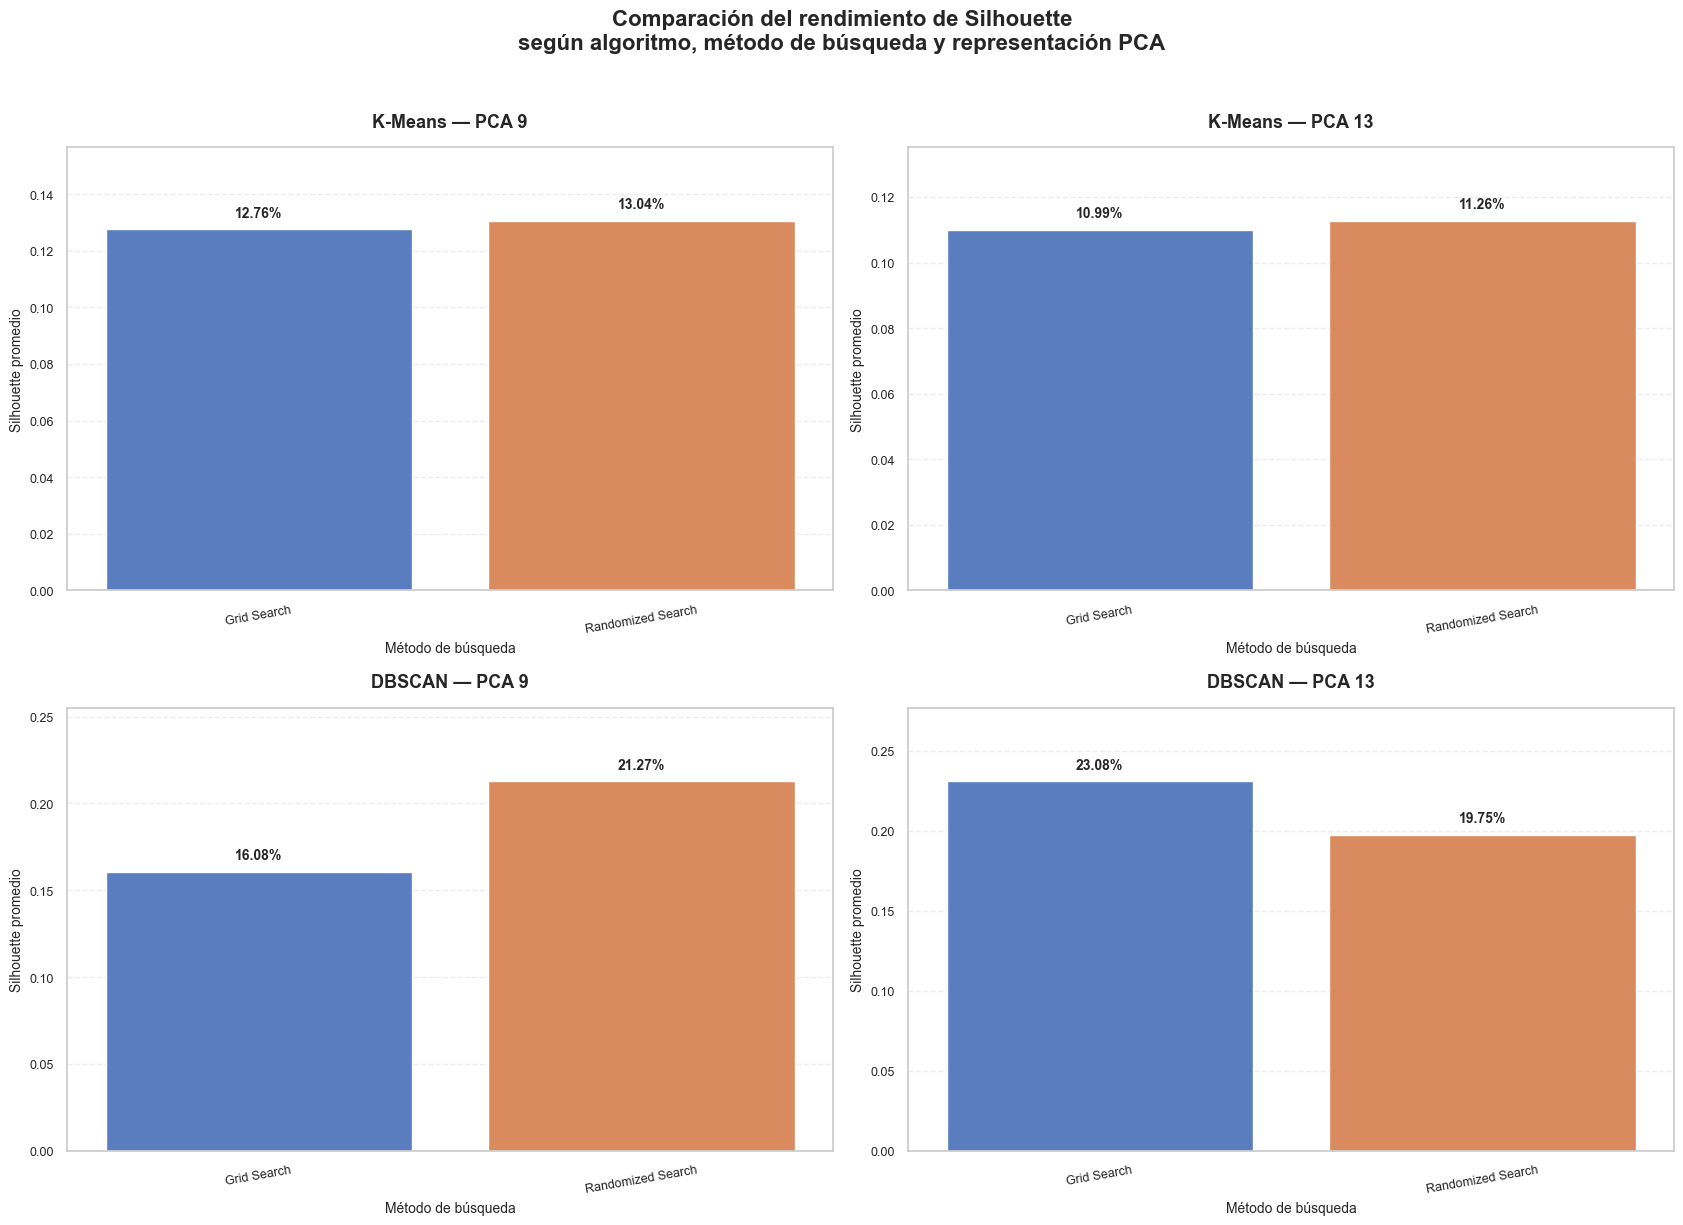

In [26]:
# Configuración visual
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

configuraciones = [
    ("K-Means", "PCA 9", resultados_kmeans),
    ("K-Means", "PCA 13", resultados_kmeans),
    ("DBSCAN", "PCA 9", resultados_dbscan),
    ("DBSCAN", "PCA 13", resultados_dbscan)
]

# Paleta profesional
paleta = sns.color_palette("muted", 2)


for ax, (algoritmo, pca, datos) in zip(
    axes.flatten(), configuraciones
):


    datos_filtrados = datos[
        (datos["PCA"] == pca)
        & (datos["Silhouette"].notna())
    ]

    # Gráfico de barras
    sns.barplot(
        data=datos_filtrados,
        x="Metodo",
        y="Silhouette",
        hue="Metodo",
        estimator="mean",
        errorbar=None,
        palette=paleta,
        ax=ax,
        legend=False,
        edgecolor="white",
        linewidth=1
    )

    # Títulos y etiquetas
    ax.set_title(
        f"{algoritmo} — {pca}",
        fontsize=13,
        fontweight="bold",
        pad=15
    )


    ax.set_xlabel("Método de búsqueda", fontsize=10)
    ax.set_ylabel("Silhouette promedio", fontsize=10)


    ax.tick_params(axis="x", rotation=10, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)

    # Formato del eje Y
    ax.yaxis.grid(True, linestyle="--", alpha=0.35)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)

    # Espacio para las etiquetas
    valores = [
        barra.get_height()
        for barra in ax.patches
    ]


    if valores:
        maximo = max(valores)
        minimo = min(0, min(valores))

        ax.set_ylim(
            minimo,
            maximo * 1.20 if maximo > 0 else 0.1
        )
    # Porcentajes encima de las barras
    for barra in ax.patches:


        altura = barra.get_height()


        if pd.notna(altura):

            ax.annotate(
                f"{altura * 100:.2f}%",
                xy=(
                    barra.get_x() + barra.get_width() / 2,
                    altura

                ),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

# Título general
fig.suptitle(
    "Comparación del rendimiento de Silhouette\n"
    "según algoritmo, método de búsqueda y representación PCA",
    fontsize=16,
    fontweight="bold",
    y=1.02
)


plt.tight_layout()
plt.show()

---

### Comparación general de métricas internas

Se comparan los promedios de Silhouette, Calinski-Harabasz y Davies-Bouldin para K-Means y DBSCAN, distinguiendo entre PCA de 9 y 13 componentes.

La interpretación debe considerar el criterio de cada métrica: Silhouette y Calinski-Harabasz se maximizan, mientras que Davies-Bouldin se minimiza. Por ello, no deben compararse sus magnitudes directamente entre sí.

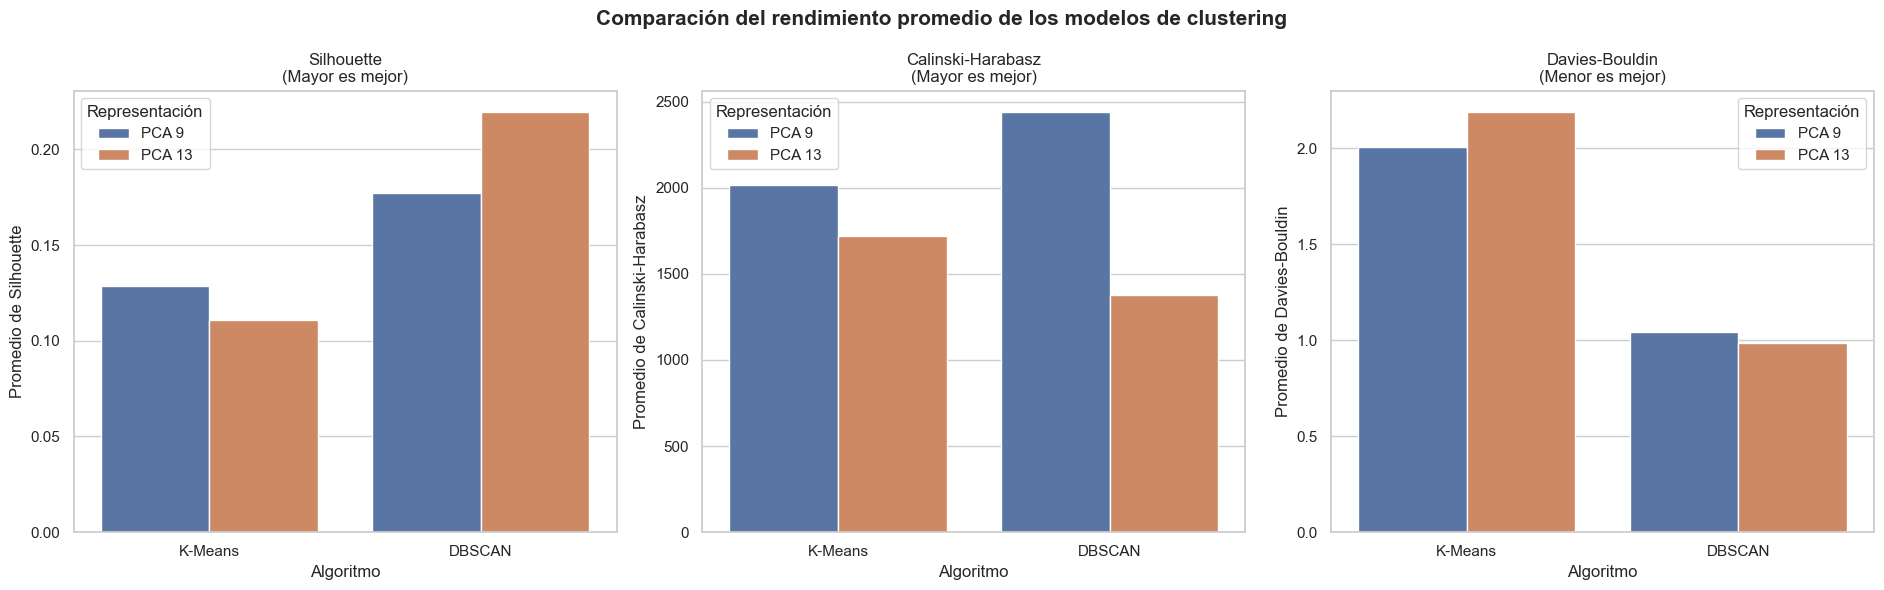

<Figure size 640x480 with 0 Axes>

In [23]:
metricas = [

    ("Silhouette", "Mayor es mejor"),

    ("Calinski-Harabasz", "Mayor es mejor"),

    ("Davies-Bouldin", "Menor es mejor")

]


fig, axes = plt.subplots(1, 3, figsize=(19, 6))


for ax, (metrica, criterio) in zip(axes, metricas):


    datos = resultados_totales.dropna(

        subset=[metrica]

    )


    sns.barplot(

        data=datos,

        x="Algoritmo",

        y=metrica,

        hue="PCA",

        estimator="mean",

        errorbar=None,

        ax=ax

    )


    ax.set_title(f"{metrica}\n({criterio})")

    ax.set_xlabel("Algoritmo")

    ax.set_ylabel(f"Promedio de {metrica}")


    ax.legend(title="Representación")


plt.suptitle(

    "Comparación del rendimiento promedio de los modelos de clustering",

    fontsize=15,

    fontweight="bold"

)


plt.tight_layout()

plt.show()


ax.set_title(f"{metrica}\n({criterio})")

ax.set_xlabel("Algoritmo")

ax.set_ylabel(metrica)


ax.legend(title="Representación")


plt.suptitle(

    "Distribución de métricas de evaluación",

    fontsize=15,

    fontweight="bold"

)


plt.tight_layout()

plt.show()


---

### Comparación de la cantidad de clusters

Se visualiza la cantidad de clusters detectados por cada algoritmo, método de búsqueda y representación PCA. Esta comparación permite identificar diferencias en la estructura encontrada por K-Means y DBSCAN.

En DBSCAN, la cantidad de clusters debe interpretarse junto con el porcentaje de ruido, ya que una configuración puede producir pocos clusters válidos y clasificar una gran proporción de observaciones como ruido.

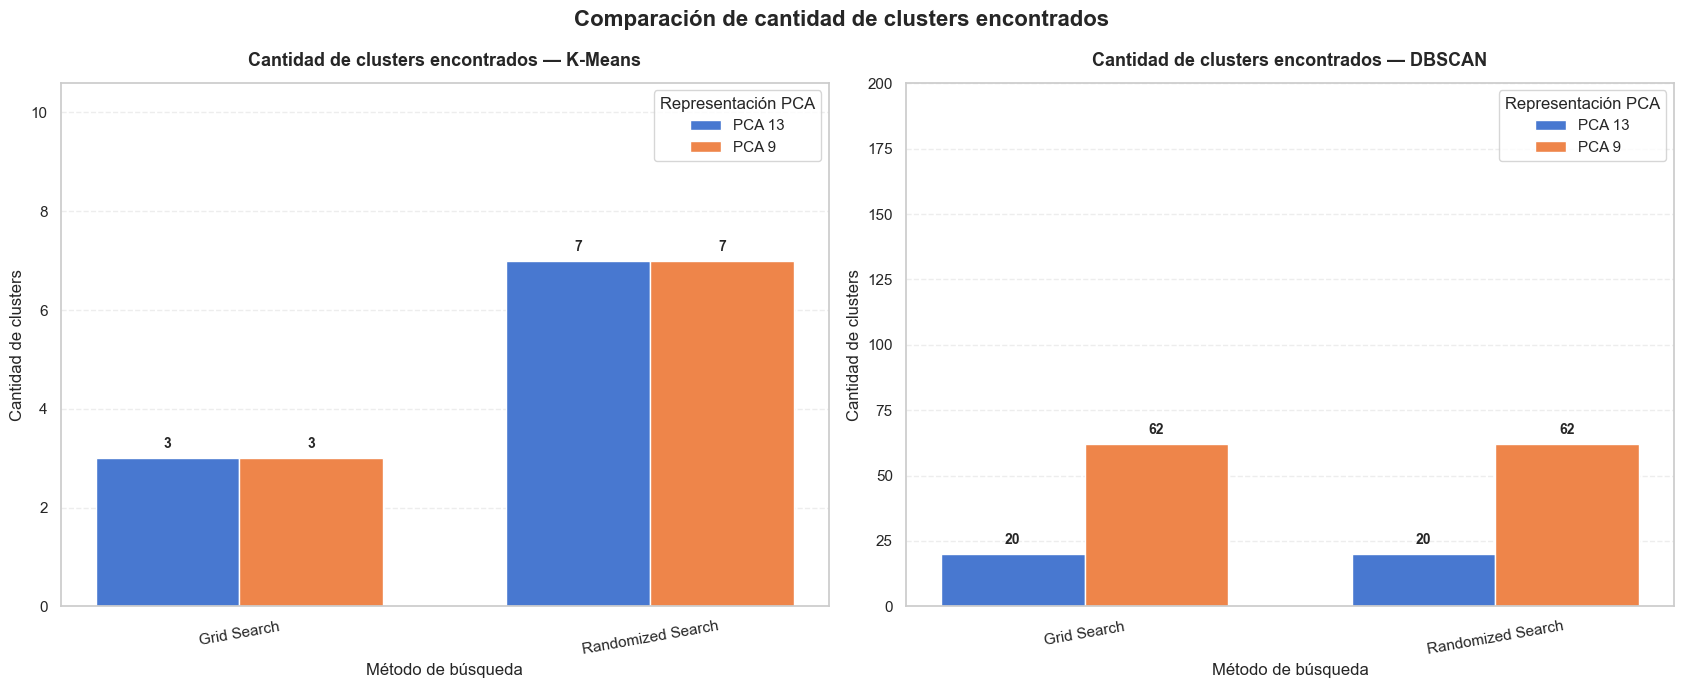

In [25]:
# Configuración visual
sns.set_theme(style="whitegrid", context="notebook")


fig, axes = plt.subplots(1, 2, figsize=(17, 7))


configuraciones = ["K-Means", "DBSCAN"]


for ax, algoritmo in zip(axes, configuraciones):

    datos = resultados_totales[
        resultados_totales["Algoritmo"] == algoritmo
    ].dropna(subset=["Clusters"]).copy()

    # Obtener métodos y representaciones
    metodos = datos["Metodo"].unique()
    pcas = sorted(datos["PCA"].unique())
    x = np.arange(len(metodos))
    ancho = 0.35
    paleta = sns.color_palette("muted", len(pcas))


    for i, pca in enumerate(pcas):

        datos_pca = (
            datos[datos["PCA"] == pca]
            .drop_duplicates(subset=["Metodo"])
            .set_index("Metodo")
            .reindex(metodos)
        )


        valores = datos_pca["Clusters"].values
        posiciones = x + (i - (len(pcas) - 1) / 2) * ancho


        barras = ax.bar(
            posiciones,
            valores,
            ancho,
            label=pca,
            color=paleta[i],
            edgecolor="white",
            linewidth=1
        )

# Etiquetas enteras sobre las barras
        for barra, valor in zip(barras, valores):


            if pd.notna(valor):

                ax.annotate(
                    f"{int(valor)}",
                    xy=(
                        barra.get_x() + barra.get_width() / 2,
                        barra.get_height()
                    ),
                    xytext=(0, 5),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    fontweight="bold"
                )


    ax.set_title(
        f"Cantidad de clusters encontrados — {algoritmo}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Método de búsqueda")
    ax.set_ylabel("Cantidad de clusters")

    ax.set_xticks(x)
    ax.set_xticklabels(metodos, rotation=10)

    ax.yaxis.set_major_locator(
        plt.MaxNLocator(integer=True)
    )

    ax.yaxis.grid(True, linestyle="--", alpha=0.35)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    ax.legend(title="Representación PCA")


    if not datos.empty:
        ax.set_ylim(
            0,
            datos["Clusters"].max() * 1.2 + 1
        )


plt.suptitle(
    "Comparación de cantidad de clusters encontrados",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()
plt.show()

---

# Entrenamiento de los modelos finales
Una vez finalizadas las búsquedas de hiperparámetros, se entrenarán los modelos definitivos de K-Means y DBSCAN utilizando las mejores configuraciones encontradas.

El procedimiento se realizará para ambas representaciones, PCA 9 y PCA 13, con el objetivo de conservar la comparación entre dimensionalidades. Los modelos se ajustarán sobre las mismas muestras de 15.000 observaciones utilizadas durante la búsqueda, manteniendo la coherencia de la evaluación y evitando un costo computacional excesivo, especialmente para DBSCAN.

La variable  `popularity_category` no se utilizará para entrenar los modelos; únicamente se conservará para los análisis posteriores.

## Selección de los mejores hiperparámetros
Se reúnen las configuraciones evaluadas por Grid Search y Randomized Search. Para cada combinación de algoritmo y representación PCA se selecciona la configuración con mayor Silhouette y, en caso de comparación, menor Davies-Bouldin.

En DBSCAN se mantienen además los criterios utilizados anteriormente: al menos dos clusters y menos de un 50% de observaciones clasificadas como ruido.

In [27]:
# Copiar los resultados válidos de las búsquedas
candidatos_finales = resultados_totales.dropna(
    subset=["Silhouette"]
).copy()

# Aplicar los criterios adicionales definidos para DBSCAN
mascara_dbscan = (
    (candidatos_finales["Algoritmo"] == "DBSCAN")
    & (candidatos_finales["Clusters"] >= 2)
    & (candidatos_finales["Ruido (%)"] < 50)
)
mascara_kmeans = candidatos_finales["Algoritmo"] == "K-Means"

candidatos_finales = candidatos_finales[mascara_kmeans | mascara_dbscan]

# Seleccionar la mejor configuración para cada algoritmo y PCA
mejores_modelos = (
    candidatos_finales
    .sort_values(
        by=["Silhouette", "Davies-Bouldin"],
        ascending=[False, True]
    )
    .drop_duplicates(subset=["Algoritmo", "PCA"], keep="first")
    .reset_index(drop=True)
)

if mejores_modelos.empty:
    raise ValueError(
        "No existen configuraciones válidas para entrenar los modelos finales. "
        "Revisa los resultados de las búsquedas anteriores."
    )

columnas_configuracion = [
    "Algoritmo", "PCA", "Metodo", "Clusters",
    "Silhouette", "Calinski-Harabasz", "Davies-Bouldin"
]

# Incorporar los hiperparámetros específicos de cada algoritmo
columnas_parametros = [
    columna for columna in [
        "n_clusters", "init", "n_init", "max_iter", "eps", "min_samples", "Ruido (%)"
    ] if columna in mejores_modelos.columns
]

display(
    mejores_modelos[columnas_configuracion + columnas_parametros]
    .round(4)
)

,Algoritmo,PCA,Metodo,Clusters,Silhouette,Calinski-Harabasz,Davies-Bouldin,n_clusters,init,n_init,max_iter,eps,min_samples,Ruido (%)
0,K-Means,PCA 9,Grid Search,3,0.1481,2628.0400,2.0662,3.0,random,10.0,300.0,NaN,NaN,NaN
1,K-Means,PCA 13,Grid Search,3,0.1311,2280.9739,2.2277,3.0,random,10.0,300.0,NaN,NaN,NaN
2,DBSCAN,PCA 9,Grid Search,7,0.0400,308.7619,1.6226,NaN,NaN,NaN,NaN,1.5,15.0,18.9733
3,DBSCAN,PCA 13,Grid Search,101,-0.2364,43.3493,1.2258,NaN,NaN,NaN,NaN,1.5,5.0,38.3867


---

## Entrenamiento de K-Means y DBSCAN
Se instancia cada algoritmo con los hiperparámetros seleccionados en el paso anterior. La representación PCA determina la matriz de entrada correspondiente.

fit_predict() realiza el ajuste del modelo y devuelve la etiqueta asignada a cada observación. En DBSCAN, la etiqueta -1 identifica las observaciones consideradas ruido.

In [28]:
# Matrices de entrada para cada representación PCA
matrices_pca = {
    "PCA 9": X_muestra_pca9,
    "PCA 13": X_muestra_pca13
}

# Diccionarios para conservar los modelos y sus asignaciones
modelos_finales = {}
asignaciones_finales = {}
resumen_entrenamiento = []

for _, configuracion in mejores_modelos.iterrows():
    algoritmo = configuracion["Algoritmo"]
    nombre_pca = configuracion["PCA"]
    X = matrices_pca[nombre_pca]

    clave = f"{algoritmo}_{nombre_pca.replace(' ', '').lower()}"

    if algoritmo == "K-Means":
        modelo = KMeans(
            n_clusters=int(configuracion["n_clusters"]),
            init=configuracion["init"],
            n_init=int(configuracion["n_init"]),
            max_iter=int(configuracion["max_iter"]),
            random_state=42
        )
    else:
        modelo = DBSCAN(
            eps=float(configuracion["eps"]),
            min_samples=int(configuracion["min_samples"])
        )

    # Ajustar el modelo y obtener las etiquetas de los clusters
    etiquetas = modelo.fit_predict(X)

    modelos_finales[clave] = modelo
    asignaciones_finales[clave] = pd.Series(
        etiquetas,
        index=X.index,
        name="cluster"
    )

    # Calcular información general del modelo entrenado
    clusters_validos = set(etiquetas) - {-1}
    porcentaje_ruido = (etiquetas == -1).mean() * 100 if algoritmo == "DBSCAN" else 0

    resumen_entrenamiento.append({
        "Modelo": clave,
        "Algoritmo": algoritmo,
        "PCA": nombre_pca,
        "Observaciones": len(X),
        "Clusters encontrados": len(clusters_validos),
        "Observaciones ruido (%)": porcentaje_ruido,
        "Silhouette búsqueda": configuracion["Silhouette"]
    })

resumen_entrenamiento = pd.DataFrame(resumen_entrenamiento)
display(resumen_entrenamiento.round(4))

,Modelo,Algoritmo,PCA,Observaciones,Clusters encontrados,Observaciones ruido (%),Silhouette búsqueda
0,K-Means_pca9,K-Means,PCA 9,15000,3,0.0000,0.1481
1,K-Means_pca13,K-Means,PCA 13,15000,3,0.0000,0.1311
2,DBSCAN_pca9,DBSCAN,PCA 9,15000,7,18.9733,0.0400
3,DBSCAN_pca13,DBSCAN,PCA 13,15000,101,38.3867,-0.2364


In [30]:
# Crear copias de trabajo para almacenar las etiquetas
datos_cluster_pca9 = df_muestra_pca9.copy()
datos_cluster_pca13 = df_muestra_pca13.copy()

for clave, etiquetas in asignaciones_finales.items():
    if "pca9" in clave.lower():
        nombre_columna = "cluster_" + clave.lower().replace("-", "_")
        datos_cluster_pca9[nombre_columna] = etiquetas
    else:
        nombre_columna = "cluster_" + clave.lower().replace("-", "_")
        datos_cluster_pca13[nombre_columna] = etiquetas

print("Asignaciones disponibles para PCA 9:")
display(datos_cluster_pca9.filter(regex="cluster").head())

print("Asignaciones disponibles para PCA 13:")
display(datos_cluster_pca13.filter(regex="cluster").head())

Asignaciones disponibles para PCA 9:


,cluster_k_means_pca9,cluster_dbscan_pca9
89860,1,1
48496,0,-1
52068,0,0
58113,0,1
17957,1,0


Asignaciones disponibles para PCA 13:


,cluster_k_means_pca13,cluster_dbscan_pca13
89860,1,-1
48496,0,-1
52068,0,-1
58113,0,-1
17957,1,0


In [31]:
resumen_clusters_finales = []

for clave, etiquetas in asignaciones_finales.items():
    conteo = etiquetas.value_counts().sort_index()

    for cluster, cantidad in conteo.items():
        resumen_clusters_finales.append({
            "Modelo": clave,
            "Cluster": "Ruido" if cluster == -1 else int(cluster),
            "Cantidad de observaciones": int(cantidad),
            "Porcentaje": cantidad / len(etiquetas) * 100
        })

tabla_clusters_finales = pd.DataFrame(resumen_clusters_finales)
display(tabla_clusters_finales.round(2))

,Modelo,Cluster,Cantidad de observaciones,Porcentaje
0,K-Means_pca9,0,7448,49.65
1,K-Means_pca9,1,4116,27.44
2,K-Means_pca9,2,3436,22.91
3,K-Means_pca13,0,7461,49.74
4,K-Means_pca13,1,4093,27.29
...,...,...,...,...
111,DBSCAN_pca13,96,5,0.03
112,DBSCAN_pca13,97,6,0.04
113,DBSCAN_pca13,98,5,0.03
114,DBSCAN_pca13,99,6,0.04


---

## Visualización tridimensional de los modelos finales
Se representan los clusters utilizando los tres primeros componentes principales. Cada gráfico permite observar la distribución espacial de las observaciones y distinguir los grupos identificados por cada configuración final. En DBSCAN, el ruido se muestra como una categoría independiente.

In [ ]:
for clave, etiquetas in asignaciones_finales.items():
    nombre_pca = "PCA 9" if "pca9" in clave.lower() else "PCA 13"
    datos_plot = matrices_pca[nombre_pca].loc[etiquetas.index, ["PC1", "PC2", "PC3"]].copy()
    datos_plot["cluster"] = etiquetas.astype(str)
    datos_plot["cluster"] = datos_plot["cluster"].replace({"-1": "Ruido"})

    fig = px.scatter_3d(
        datos_plot,
        x="PC1",
        y="PC2",
        z="PC3",
        color="cluster",
        title=f"Distribución de clusters — {clave}",
        labels={
            "PC1": "Componente principal 1",
            "PC2": "Componente principal 2",
            "PC3": "Componente principal 3",
            "cluster": "Cluster"
        },
        opacity=0.7
    )

    fig.update_traces(marker=dict(size=3))
    fig.update_layout(
        template="plotly_white",
        height=700,
        legend_title_text="Grupo"
    )
    fig.show()


---

## Conclusiones

La búsqueda permite comparar distintas configuraciones de K-Means y DBSCAN utilizando dos representaciones PCA y dos estrategias de exploración de hiperparámetros.

Para interpretar los resultados finales se deben considerar conjuntamente los siguientes aspectos:

1. **Calidad de agrupamiento:** priorizar valores altos de Silhouette y Calinski-Harabasz, junto con valores bajos de Davies-Bouldin.
2. **Cantidad de clusters:** comprobar que la cantidad de grupos encontrados sea útil para el análisis y no solamente un resultado numérico.
3. **Ruido en DBSCAN:** considerar el porcentaje de observaciones etiquetadas como ruido antes de seleccionar una configuración.
4. **Representación PCA:** comparar si utilizar 9 o 13 componentes produce una mejora consistente en las métricas.
5. **Método de búsqueda:** evaluar si Randomized Search encuentra configuraciones competitivas con menos evaluaciones que Grid Search.

Las métricas utilizadas corresponden a **criterios internos de evaluación no supervisada**. La variable `popularity_category` se utiliza para mantener la distribución de las muestras, pero no participa en el ajuste de los algoritmos ni en el cálculo de estas métricas. Por lo tanto, los resultados describen la estructura de los grupos según las variables PCA y no el nivel de acierto respecto de una categoría objetivo.